In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
# 1. Create a full DataFrame with multiple attributes
data = {
    'Flavor': ['Vanilla', 'Chocolate', 'Strawberry', 'Lemon Sorbet', 'Mint Choc Chip'],
    'Sweetness': [8, 9, 7, 3, 8],
    'Creaminess': [9, 9, 8, 2, 8],
    'Price_INR': [120, 140, 130, 90, 150] # Extra feature we won't cluster by
}

df = pd.DataFrame(data)
print("--- Full DataFrame ---")
print(df)

--- Full DataFrame ---
           Flavor  Sweetness  Creaminess  Price_INR
0         Vanilla          8           9        120
1       Chocolate          9           9        140
2      Strawberry          7           8        130
3    Lemon Sorbet          3           2         90
4  Mint Choc Chip          8           8        150


In [3]:
# 2. Separate what is required:
# Extract only the numerical features we want to measure distance across
features = df[['Sweetness', 'Creaminess']]
print("--- Features for Clustering ---")
print(features)

# 3. Perform hierarchical clustering
'''
Perform hierarchical clustering using the Ward method.
This method minimizes the variance of clusters being merged.
Other methods include 'single', 'complete', and 'average', each using a different strategy to measure the distance between clusters.
The choice of method can affect the shape and size of the resulting clusters.
Method Ward  : Particularly useful when you want to minimize the variance within clusters.
Method Single : Considers the minimum distance between points in different clusters when merging.
Method Complete : Considers the maximum distance between points in different clusters when merging.
Method Average : Considers the average distance between points in different clusters when merging.
'''
linked = linkage(features, method='ward')
# calculate cophenetic correlation coefficient
from scipy.cluster.hierarchy import cophenet
from scipy.spatial.distance import pdist
c, coph_dists = cophenet(linked, pdist(features))
print("Cophenetic Correlation Coefficient:", c)


--- Features for Clustering ---
   Sweetness  Creaminess
0          8           9
1          9           9
2          7           8
3          3           2
4          8           8
Cophenetic Correlation Coefficient: 0.9860390726373361


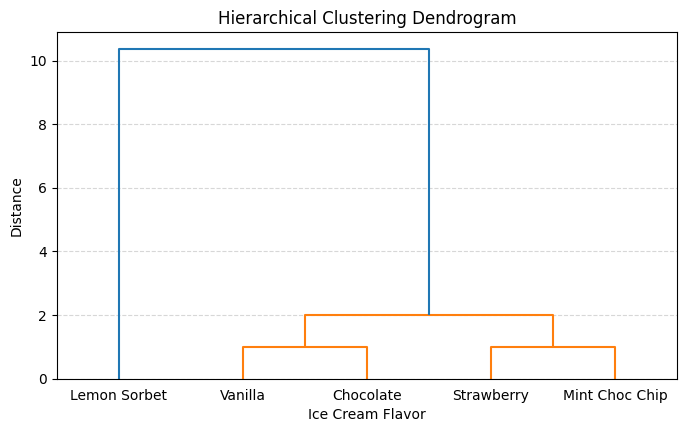

In [4]:
# step 4 Plot the dendrogram
plt.figure(figsize=(8, 4.5))
dendrogram(linked,
           labels=df['Flavor'].values,
           leaf_rotation=0,
           leaf_font_size=10)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Ice Cream Flavor')
plt.ylabel('Distance')
plt.grid(axis='y',linestyle='--',alpha=0.5)
plt.show()